<a href="https://colab.research.google.com/github/donpayagala/CN6005-Applied-AI/blob/main/Task3_AIAgent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 — CineGuide: a Tool-Using Movie Recommendation Agent

**Agent type:** Movie Recommendation Agent.

CineGuide answers questions such as *"highly rated 80s sci-fi"*, *"something like Toy Story"* or *"who directed The Dark Knight?"*. It searches a predefined knowledge base of **1,000 popular films** (TMDB 5000 dataset) and uses a Large Language Model to **decide which search tool to call, with which filters**, and to write a grounded answer.

The agent logic lives in the reusable, unit-tested Python package [`movie_agent/`](movie_agent/); this notebook demonstrates, explains and evaluates it. A web chat UI is in `app.py` (`streamlit run app.py`).

| Section | Brief requirement |
|---|---|
| 1. Setup | – |
| 2. Agent design & architecture | 3.1 goal, knowledge source, role of LLM, response process, diagram |
| 3. Knowledge base | 3.1 knowledge source |
| 4. Implementation walkthrough | 3.2 accept question → search → LLM → response |
| 5. Live interactions | demo (≥ 3 interactions) |
| 6. Evaluation | 3.3 performance, strengths & limitations, agent vs chatbot |

## 1. Setup
**On Colab** the cell below clones the repository so the `movie_agent` package is available.

**LLM key (free):** create a key at [console.groq.com](https://console.groq.com/keys) (or [Google AI Studio](https://aistudio.google.com/apikey) for Gemini) and add it as a Colab secret named `GROQ_API_KEY` / `GEMINI_API_KEY`, or put it in a `.env` file locally (see `.env.example`). **Without a key the notebook still runs** in a retrieval-only offline mode.

In [1]:
import os
import sys
import subprocess

REPO_URL = "https://github.com/donpayagala/CN6005-Applied-AI.git"
if not os.path.isdir("movie_agent"):                      # running outside the repo (e.g. Colab)
    if not os.path.isdir("CN6005-Applied-AI"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("CN6005-Applied-AI")
sys.path.insert(0, os.getcwd())

# Load API keys from Colab secrets or a local .env file (never hard-code keys in a notebook!)
KEY_NAMES = ["GROQ_API_KEY", "GEMINI_API_KEY", "OPENAI_API_KEY", "ANTHROPIC_API_KEY", "LLM_PROVIDER", "LLM_MODEL"]
try:
    from google.colab import userdata
    for name in KEY_NAMES:
        try:
            os.environ[name] = userdata.get(name)
        except Exception:
            pass
except ImportError:
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except ImportError:
        pass

In [2]:
%pip install -q -r requirements-agent.txt

In [3]:
import json
import pathlib
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from IPython.display import Markdown, display

from movie_agent import HybridRetriever, MovieAgent, MovieTools, load_knowledge_base
from movie_agent.agent import SYSTEM_PROMPT
from movie_agent.tools import TOOL_SCHEMAS
from movie_agent.llm import make_client
from movie_agent.evaluation import retrieval_metrics, run_scenarios

FIG_DIR = pathlib.Path("screenshots/task3")
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Agent design (3.1)

### 2.1 Goal
Help a user **find a film to watch** — by mood, plot, genre, period, rating, cast or similarity to a film they already like — and answer factual questions about films, **using only trustworthy data** from the knowledge base.

### 2.2 Knowledge source
The **TMDB 5000 Movie Dataset** (Kaggle, The Movie Database). We keep the **1,000 most-voted films** (≥ 100 votes) so the knowledge base is small, well-known and reliable. For each film we store title, year, genres, director, top-billed cast, keywords, rating, runtime and plot overview, and build one searchable text "document" per film.

### 2.3 Role of the LLM
The LLM is **not** the source of facts. It acts as the agent's **reasoning and language layer**:
1. **Understands** the request and translates it into a structured tool call (e.g. "90s sci-fi rated above 7" → `search_movies(query=…, genre="Science Fiction", year_from=1990, year_to=1999, min_rating=7)`).
2. **Decides** which tool to use and whether more than one step is needed (e.g. look up a film, then find similar ones).
3. **Writes** a concise, friendly answer that is grounded in the tool results, and declines out-of-scope questions.

### 2.4 How the agent responds to a query (plan → act → observe → answer)
1. The user's message is added to the conversation memory.
2. The LLM receives the conversation + the tool definitions and either answers or **requests a tool call**.
3. The tool runs **hybrid retrieval** over the knowledge base (TF-IDF for exact words + Sentence-BERT for meaning) with any filters, and returns compact JSON.
4. The result is fed back to the LLM ("observation"). Steps 2–4 repeat up to 4 times.
5. The final answer is returned with the list of **source films** and the **tool trace**, so every recommendation can be checked.

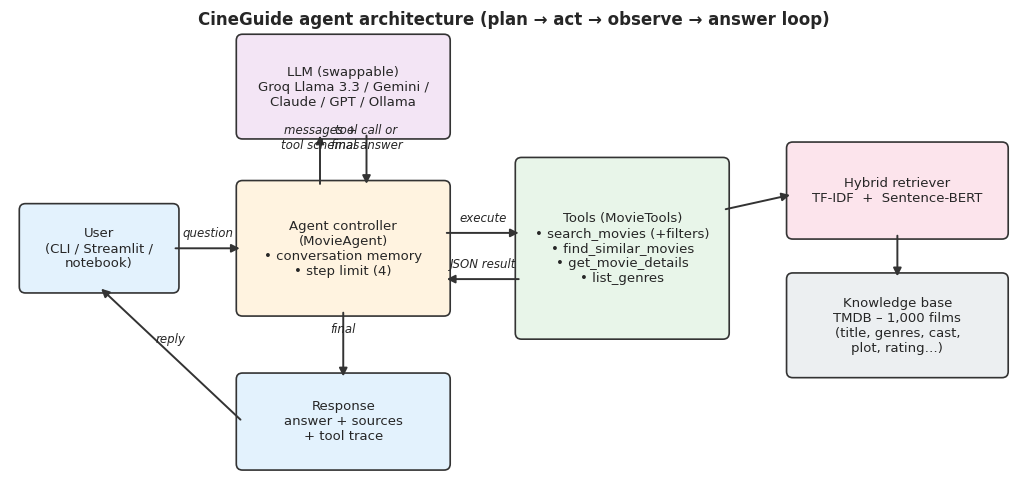

In [4]:
def draw_architecture():
    fig, ax = plt.subplots(figsize=(13, 6.2))
    ax.set_xlim(0, 13); ax.set_ylim(0, 6.2); ax.axis("off")

    def box(x, y, w, h, text, color):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.08", fc=color, ec="#333", lw=1.2))
        ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=9.5, wrap=True)

    def arrow(x1, y1, x2, y2, label="", style="-|>"):
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle=style, lw=1.4, color="#333"))
        if label:
            ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.15, label, ha="center", fontsize=8.5, style="italic")

    box(0.2, 2.6, 1.9, 1.0, "User\n(CLI / Streamlit /\nnotebook)", "#e3f2fd")
    box(3.0, 2.3, 2.6, 1.6, "Agent controller\n(MovieAgent)\n• conversation memory\n• step limit (4)", "#fff3e0")
    box(3.0, 4.6, 2.6, 1.2, "LLM (swappable)\nGroq Llama 3.3 / Gemini /\nClaude / GPT / Ollama", "#f3e5f5")
    box(6.6, 2.0, 2.6, 2.2, "Tools (MovieTools)\n• search_movies (+filters)\n• find_similar_movies\n• get_movie_details\n• list_genres", "#e8f5e9")
    box(10.1, 3.3, 2.7, 1.1, "Hybrid retriever\nTF-IDF  +  Sentence-BERT", "#fce4ec")
    box(10.1, 1.5, 2.7, 1.2, "Knowledge base\nTMDB – 1,000 films\n(title, genres, cast,\nplot, rating…)", "#eceff1")
    box(3.0, 0.3, 2.6, 1.1, "Response\nanswer + sources\n+ tool trace", "#e3f2fd")

    arrow(2.1, 3.1, 3.0, 3.1, "question")
    arrow(4.0, 3.9, 4.0, 4.6, "messages +\ntool schemas")
    arrow(4.6, 4.6, 4.6, 3.9, "tool call or\nfinal answer")
    arrow(5.6, 3.3, 6.6, 3.3, "execute")
    arrow(6.6, 2.7, 5.6, 2.7, "JSON result")
    arrow(9.2, 3.6, 10.1, 3.8)
    arrow(11.45, 3.3, 11.45, 2.7)
    arrow(4.3, 2.3, 4.3, 1.4, "final")
    arrow(3.0, 0.85, 1.15, 2.6, "reply")
    ax.text(6.5, 6.0, "CineGuide agent architecture (plan → act → observe → answer loop)",
            ha="center", fontsize=12, fontweight="bold")
    plt.savefig(FIG_DIR / "architecture.png", dpi=150, bbox_inches="tight")
    plt.show()


draw_architecture()

### 2.5 The tools the LLM can call
Each tool is described to the LLM with a JSON schema (OpenAI function-calling format, which Groq, Gemini, Claude, OpenAI and Ollama all support).

In [5]:
pd.DataFrame([{"tool": t["function"]["name"], "description": t["function"]["description"],
               "arguments": ", ".join(t["function"]["parameters"]["properties"]) or "-"}
              for t in TOOL_SCHEMAS]).set_index("tool")

,description,arguments
tool,,
search_movies,"Search the movie knowledge base by plot, mood,...","query, genre, year_from, year_to, min_rating, k"
find_similar_movies,Find movies similar to a movie the user names.,"title, k"
get_movie_details,"Get full details (year, genres, director, cast...",title
list_genres,List the genres available in the knowledge base.,-


In [6]:
print(SYSTEM_PROMPT)

You are CineGuide, a friendly movie recommendation agent.

Rules:
1. Use the tools to look movies up BEFORE recommending. Only recommend or describe
   movies that appear in tool results - never invent titles or facts.
2. Turn the user's request into tool arguments: e.g. "90s sci-fi" -> genre="Science Fiction",
   year_from=1990, year_to=1999. Use find_similar_movies for "movies like X" and
   get_movie_details for questions about one film.
3. Recommend at most 5 movies. For each give the title, year and one short reason
   that is supported by the tool data.
4. If a tool returns nothing useful, say so honestly and suggest how to rephrase.
5. If the request is not about movies, politely explain that you only help with movies.
6. Remember earlier turns of the conversation (e.g. "something shorter", "more like the first one").



## 3. Knowledge base

In [7]:
kb = load_knowledge_base(top_n=1000)
print(f"{len(kb)} films, {kb['year'].min():.0f}–{kb['year'].max():.0f}")
kb[["title", "year", "genres", "director", "cast", "rating", "runtime"]].head()

Using Colab cache for faster access to the 'tmdb-movie-metadata' dataset.
1000 films, 1937–2016


,title,year,genres,director,cast,rating,runtime
0,Inception,2010.0,"[Action, Thriller, Science Fiction, Mystery, A...",Christopher Nolan,"[Leonardo DiCaprio, Joseph Gordon-Levitt, Elle...",8.1,148.0
1,The Dark Knight,2008.0,"[Drama, Action, Crime, Thriller]",Christopher Nolan,"[Christian Bale, Heath Ledger, Aaron Eckhart, ...",8.2,152.0
2,Avatar,2009.0,"[Action, Adventure, Fantasy, Science Fiction]",James Cameron,"[Sam Worthington, Zoe Saldana, Sigourney Weave...",7.2,162.0
3,The Avengers,2012.0,"[Science Fiction, Action, Adventure]",Joss Whedon,"[Robert Downey Jr., Chris Evans, Mark Ruffalo,...",7.4,143.0
4,Deadpool,2016.0,"[Action, Adventure, Comedy]",Tim Miller,"[Ryan Reynolds, Morena Baccarin, Ed Skrein, T....",7.4,108.0


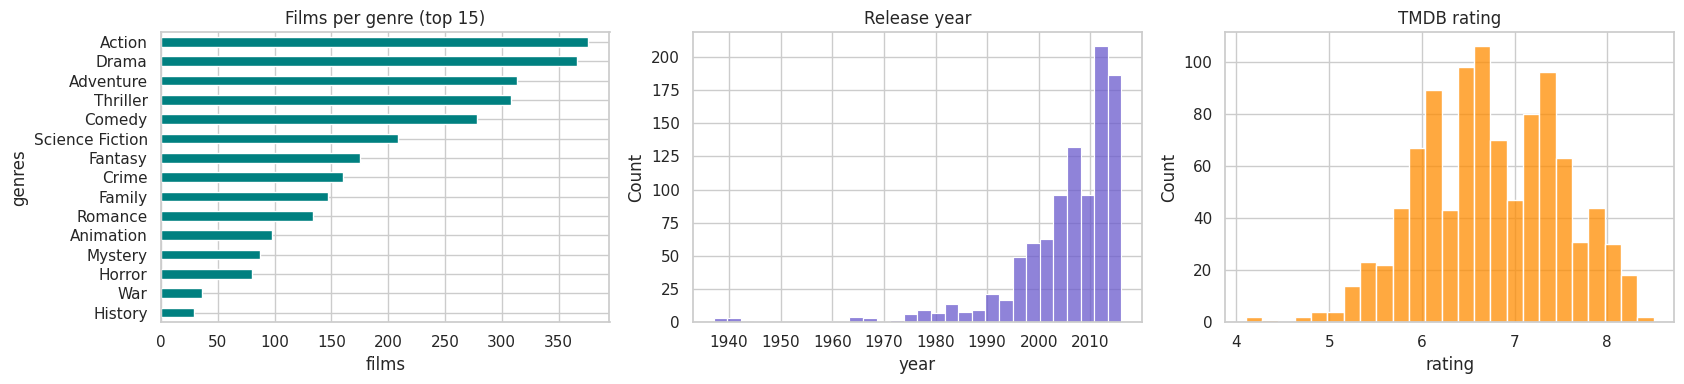

Example document indexed by the retriever:

Inception (2010). Genres: Action, Thriller, Science Fiction, Mystery, Adventure. Director: Christopher Nolan.
Starring: Leonardo DiCaprio, Joseph Gordon-Levitt, Ellen Page, Tom Hardy. Keywords: loss of lover, dream,
kidnapping, sleep, subconsciousness, heist, redemption, female hero. Plot: Cobb, a skilled thief who commits
corporate espionage by infiltrating the subconscious of his targets is offered a chance to regain his old life
as payment for a task considered to be impossible: "inception", the implantation of another person's idea into
a target's subconscious.


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
kb.explode("genres")["genres"].value_counts().head(15).sort_values().plot.barh(ax=axes[0], color="teal")
axes[0].set(title="Films per genre (top 15)", xlabel="films")
sns.histplot(kb["year"], bins=30, ax=axes[1], color="slateblue")
axes[1].set(title="Release year")
sns.histplot(kb["rating"], bins=25, ax=axes[2], color="darkorange")
axes[2].set(title="TMDB rating")
plt.tight_layout()
plt.savefig(FIG_DIR / "knowledge_base_overview.png", dpi=150, bbox_inches="tight")
plt.show()

print("Example document indexed by the retriever:\n")
print(textwrap.fill(kb.loc[kb["title"] == "Inception", "doc"].iloc[0], 110))

**Knowledge-base notes.** The data is skewed towards Drama, Comedy, Thriller and Action and towards films released after 1995, because TMDB vote counts favour recent popular films. This bias is inherited by the agent (see limitations).

## 4. Implementation walkthrough (3.2)
### 4.1 Searching the knowledge base — hybrid retrieval
The retriever combines two scores, each scaled to 0–1:

$$\text{score} = \alpha \cdot \text{TF-IDF cosine} + (1-\alpha) \cdot \text{Sentence-BERT cosine}, \quad \alpha = 0.4$$

In [9]:
retriever = HybridRetriever(kb, mode="hybrid", alpha=0.4)
print("Retriever mode:", retriever.mode)
retriever.search("a feel-good film that will make me cry", k=5)[["title", "year", "genres", "rating", "score"]]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Retriever mode: hybrid


,title,year,genres,rating,score
855,It's a Wonderful Life,1946.0,"[Drama, Family, Fantasy]",8.0,0.810863
520,10 Things I Hate About You,1999.0,"[Comedy, Romance, Drama]",7.3,0.744330
190,A Good Day to Die Hard,2013.0,"[Action, Thriller]",5.2,0.686624
390,Hot Fuzz,2007.0,"[Crime, Action, Comedy]",7.4,0.661084
392,Saw,2004.0,"[Horror, Mystery, Crime]",7.2,0.660506


### 4.2 Tools on their own (no LLM)

In [10]:
tools = MovieTools(retriever)
print(json.dumps(tools.search_movies("space adventure", genre="Science Fiction", year_from=1977, year_to=1989, k=3), indent=2)[:1200])

{
  "results": [
    {
      "title": "Aliens",
      "year": 1986,
      "genres": [
        "Horror",
        "Action",
        "Thriller",
        "Science Fiction"
      ],
      "director": "James Cameron",
      "rating": 7.7,
      "overview": "When Ripley's lifepod is found by a salvage crew over 50 years later, she finds that terra-formers are on the very planet they found the alien species. When the company sends a family of colonists out to investigate her..."
    },
    {
      "title": "Alien",
      "year": 1979,
      "genres": [
        "Horror",
        "Action",
        "Thriller",
        "Science Fiction"
      ],
      "director": "Ridley Scott",
      "rating": 7.9,
      "overview": "During its return to the earth, commercial spaceship Nostromo intercepts a distress signal from a distant planet. When a three-member team of the crew discovers a chamber containing thousands of eggs on the planet, a..."
    },
    {
      "title": "The Thing",
      "year": 1982,
  

In [11]:
print(json.dumps(tools.find_similar_movies("The Matrix", k=5), indent=1)[:900])

{
 "reference": "The Matrix",
 "results": [
  {
   "title": "The Matrix Revolutions",
   "year": 2003,
   "genres": [
    "Adventure",
    "Action",
    "Thriller",
    "Science Fiction"
   ],
   "director": "Lilly Wachowski",
   "rating": 6.4,
   "overview": "The human city of Zion defends itself against the massive invasion of the machines as Neo fights to end the war at another front while also opposing the rogue Agent Smith."
  },
  {
   "title": "The Matrix Reloaded",
   "year": 2003,
   "genres": [
    "Adventure",
    "Action",
    "Thriller",
    "Science Fiction"
   ],
   "director": "Lilly Wachowski",
   "rating": 6.7,
   "overview": "Six months after the events depicted in The Matrix, Neo has proved to be a good omen for the free humans, as more and more humans are being freed from the matrix and brought to Zion, the one and only stronghold of the..."
  },
  {
   "title": "9",


### 4.3 Connecting the LLM
`make_client()` picks the first provider whose API key is set (or `LLM_PROVIDER`). If none is configured the agent runs in offline mode.

In [12]:
llm = make_client()
agent = MovieAgent(tools, llm=llm, max_steps=4)
print("LLM:", f"{llm.provider} / {llm.model}" if llm else "none -> offline retrieval-only mode")


def chat(question: str) -> None:
    """Ask the agent and display the answer with its tool trace."""
    resp = agent.ask(question)
    trace = "\n".join(f"  {i + 1}. `{c['tool']}({json.dumps(c['args'], ensure_ascii=False)})`"
                      for i, c in enumerate(resp.tool_calls)) or "  (no tool used)"
    display(Markdown(f"**🧑 User:** {question}\n\n**🎬 CineGuide:** {resp.answer}\n\n"
                     f"<small>Tool trace:\n{trace}\n\nSources: {', '.join(resp.sources[:8]) or '-'} · "
                     f"{resp.latency_s:.1f}s · {resp.steps} step(s)</small>"))

LLM: none -> offline retrieval-only mode


## 5. Live interactions
Each interaction shows the answer **and** the tool calls the LLM chose — the evidence that the agent reasons about *how* to search instead of just chatting.

In [13]:
chat("I loved Inception. Can you recommend a few other mind-bending films?")

**🧑 User:** I loved Inception. Can you recommend a few other mind-bending films?

**🎬 CineGuide:** (Offline mode - no LLM configured.) Closest matches:
- Inception (2010) - Action, Thriller, Science Fiction, rated 8.1/10
- Now You See Me 2 (2016) - Action, Adventure, Comedy, rated 6.7/10
- Trance (2013) - Thriller, Crime, Drama, rated 6.5/10

<small>Tool trace:
  1. `search_movies({"query": "I loved Inception. Can you recommend a few other mind-bending films?", "k": 3})`

Sources: Inception, Now You See Me 2, Trance · 0.1s · 1 step(s)</small>

In [14]:
chat("Recommend some highly rated science fiction films from the 1980s.")

**🧑 User:** Recommend some highly rated science fiction films from the 1980s.

**🎬 CineGuide:** (Offline mode - no LLM configured.) Closest matches:
- Mars Attacks! (1996) - Comedy, Fantasy, Science Fiction, rated 6.1/10
- X-Men: Apocalypse (2016) - Science Fiction, rated 6.4/10
- Pixels (2015) - Action, Comedy, Science Fiction, rated 5.6/10

<small>Tool trace:
  1. `search_movies({"query": "Recommend some highly rated science fiction films from the 1980s.", "k": 3})`

Sources: Mars Attacks!, X-Men: Apocalypse, Pixels · 0.0s · 1 step(s)</small>

In [15]:
chat("Who directed The Dark Knight, who stars in it and how long is it?")

**🧑 User:** Who directed The Dark Knight, who stars in it and how long is it?

**🎬 CineGuide:** (Offline mode - no LLM configured.) Closest matches:
- The Dark Knight Rises (2012) - Action, Crime, Drama, rated 7.6/10
- The Dark Knight (2008) - Drama, Action, Crime, rated 8.2/10
- Batman (1989) - Fantasy, Action, rated 7.0/10

<small>Tool trace:
  1. `search_movies({"query": "Who directed The Dark Knight, who stars in it and how long is it?", "k": 3})`

Sources: The Dark Knight Rises, The Dark Knight, Batman · 0.0s · 1 step(s)</small>

In [16]:
# Multi-turn: the agent must remember the previous answer
chat("I want an animated movie to watch with my kids tonight.")
chat("Great, can you suggest something similar to the first one you mentioned?")

**🧑 User:** I want an animated movie to watch with my kids tonight.

**🎬 CineGuide:** (Offline mode - no LLM configured.) Closest matches:
- Ice Age: The Meltdown (2006) - Animation, Family, Comedy, rated 6.5/10
- Sausage Party (2016) - Adventure, Animation, Comedy, rated 5.6/10
- The Lego Movie (2014) - Adventure, Animation, Comedy, rated 7.5/10

<small>Tool trace:
  1. `search_movies({"query": "I want an animated movie to watch with my kids tonight.", "k": 3})`

Sources: Ice Age: The Meltdown, Sausage Party, The Lego Movie · 0.1s · 1 step(s)</small>

**🧑 User:** Great, can you suggest something similar to the first one you mentioned?

**🎬 CineGuide:** I could not find matching movies in my knowledge base. I can only help with movie recommendations - try describing a plot, genre or actor.

<small>Tool trace:
  1. `search_movies({"query": "Great, can you suggest something similar to the first one you mentioned?", "k": 3})`

Sources: The Shallows, Oz: The Great and Powerful, Evan Almighty · 0.0s · 1 step(s)</small>

In [17]:
chat("What's the weather like in London today?")   # out of scope -> should politely decline
agent.reset()

**🧑 User:** What's the weather like in London today?

**🎬 CineGuide:** I could not find matching movies in my knowledge base. I can only help with movie recommendations - try describing a plot, genre or actor.

<small>Tool trace:
  1. `search_movies({"query": "What's the weather like in London today?", "k": 3})`

Sources: Cloudy with a Chance of Meatballs, London Has Fallen, 28 Days Later · 0.1s · 1 step(s)</small>

## 6. Evaluation (3.3)
### 6.1 Retrieval quality
20 description-only queries (no title words, e.g. *"clownfish father crosses the ocean to find his son"*) with a known correct film. We measure:
* **Hit@1 / Hit@5** — is the correct film ranked first / in the top 5?
* **MRR** (mean reciprocal rank) — 1 if first, ½ if second, …

and compare **lexical only**, **semantic only** and **hybrid** retrieval.

In [18]:
modes = {"Lexical (TF-IDF)": HybridRetriever(kb, mode="lexical"),
         "Semantic (SBERT)": HybridRetriever(kb, mode="semantic"),
         "Hybrid (α=0.4)": retriever}
retrieval_table = pd.DataFrame({name: retrieval_metrics(r) for name, r in modes.items()}).T
retrieval_table

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

,queries,hit@1,hit@5,MRR
Lexical (TF-IDF),20.0,0.60,0.90,0.729167
Semantic (SBERT),20.0,0.75,1.00,0.839167
Hybrid (α=0.4),20.0,0.90,0.95,0.912500


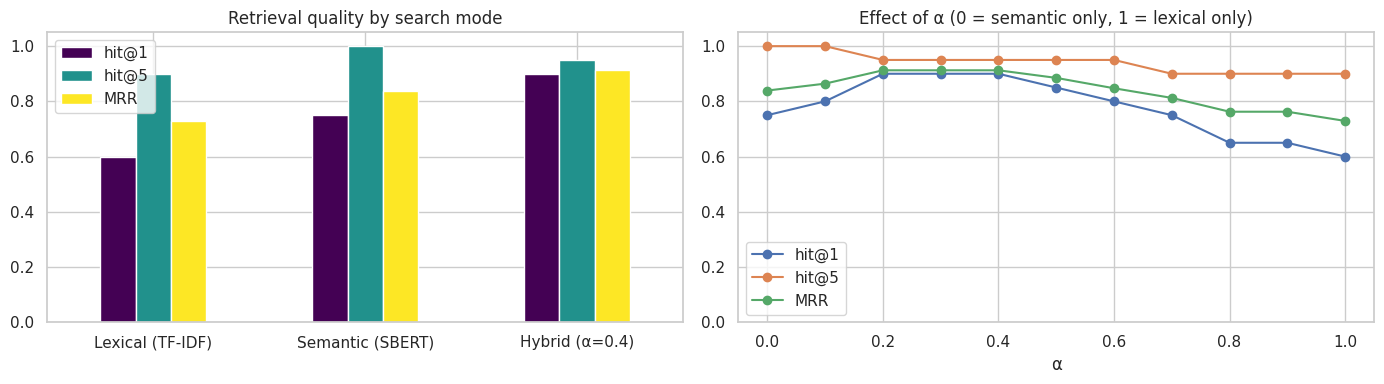

In [19]:
alphas = np.round(np.linspace(0, 1, 11), 1)
sweep = []
for a in alphas:
    retriever.alpha = a
    sweep.append({"alpha": a, **retrieval_metrics(retriever)})
retriever.alpha = 0.4
sweep = pd.DataFrame(sweep).set_index("alpha")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
retrieval_table[["hit@1", "hit@5", "MRR"]].plot.bar(ax=axes[0], rot=0, colormap="viridis", ylim=(0, 1.05))
axes[0].set_title("Retrieval quality by search mode")
sweep[["hit@1", "hit@5", "MRR"]].plot(ax=axes[1], marker="o", ylim=(0, 1.05))
axes[1].set(title="Effect of α (0 = semantic only, 1 = lexical only)", xlabel="α")
plt.tight_layout()
plt.savefig(FIG_DIR / "retrieval_evaluation.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 End-to-end scenario tests
Seven scripted scenarios test the whole agent: plot search, genre + decade filters, "similar to", factual details, multi-turn memory, an out-of-scope question and a non-existent film. Automatic checks:
* **right_tool** — the LLM chose the appropriate tool;
* **filters_respected** — every recommended film satisfies the year constraint;
* **facts_correct** — key facts appear in the answer;
* **declined_correctly** — no films are invented for out-of-scope / unknown requests;
* **grounded** — share of films mentioned in the answer that actually came from a tool result (1.0 = no hallucinated recommendations).

In [20]:
scenario_results = run_scenarios(agent)
scenario_results.to_csv(FIG_DIR / "scenario_results.csv", index=False)
print(f"Scenarios passed: {scenario_results['passed'].sum()}/{len(scenario_results)} | "
      f"mean groundedness: {scenario_results['grounded'].mean():.2f} | "
      f"mean latency: {scenario_results['latency_s'].mean():.1f}s")
scenario_results.drop(columns="answer")

Scenarios passed: 2/7 | mean groundedness: 0.95 | mean latency: 0.1s


,scenario,passed,right_tool,grounded,tools_used,latency_s,filters_respected,facts_correct,declined_correctly
0,Plot-based search,True,True,1.00,search_movies,0.05,NaN,NaN,NaN
1,Genre + decade filter,False,True,1.00,search_movies,0.04,False,NaN,NaN
2,Similar movies,False,False,1.00,search_movies,0.06,NaN,NaN,NaN
3,Movie details,False,False,0.75,search_movies,0.06,NaN,False,NaN
4,Multi-turn memory,False,False,NaN,"search_movies, search_movies",0.11,NaN,NaN,NaN
5,Out of scope,True,NaN,NaN,search_movies,0.05,NaN,NaN,True
6,Unknown film,False,NaN,1.00,search_movies,0.05,NaN,NaN,False


In [21]:
with pd.option_context("display.max_colwidth", 400):
    display(scenario_results[["scenario", "answer"]])

,scenario,answer
0,Plot-based search,"(Offline mode - no LLM configured.) Closest matches:\n- Now You See Me 2 (2016) - Action, Adventure, Comedy, rated 6.7/10\n- Trance (2013) - Thriller, Crime, Drama, rated 6.5/10\n- Now You See Me (2013) - Thriller, Crime, rated 7.3/10"
1,Genre + decade filter,"(Offline mode - no LLM configured.) Closest matches:\n- Mars Attacks! (1996) - Comedy, Fantasy, Science Fiction, rated 6.1/10\n- Pixels (2015) - Action, Comedy, Science Fiction, rated 5.6/10\n- X-Men: Apocalypse (2016) - Science Fiction, rated 6.4/10"
2,Similar movies,"(Offline mode - no LLM configured.) Closest matches:\n- Toy Story 3 (2010) - Animation, Family, Comedy, rated 7.6/10\n- Toy Story (1995) - Animation, Comedy, Family, rated 7.7/10\n- Toy Story 2 (1999) - Animation, Comedy, Family, rated 7.3/10"
3,Movie details,"(Offline mode - no LLM configured.) Closest matches:\n- The Dark Knight Rises (2012) - Action, Crime, Drama, rated 7.6/10\n- The Dark Knight (2008) - Drama, Action, Crime, rated 8.2/10\n- Batman (1989) - Fantasy, Action, rated 7.0/10"
4,Multi-turn memory,"I could not find matching movies in my knowledge base. I can only help with movie recommendations - try describing a plot, genre or actor."
5,Out of scope,"I could not find matching movies in my knowledge base. I can only help with movie recommendations - try describing a plot, genre or actor."
6,Unknown film,"(Offline mode - no LLM configured.) Closest matches:\n- Superman Returns (2006) - Adventure, Fantasy, Action, rated 5.4/10\n- Knocked Up (2007) - Comedy, Romance, Drama, rated 6.2/10\n- Hail, Caesar! (2016) - Comedy, Drama, Mystery, rated 5.7/10"


### 6.3 Performance, strengths and limitations

*(Read together with the tables above — numbers depend on the LLM provider used.)*

**Performance.** Hybrid retrieval combines the precision of TF-IDF on names and rare words with the robustness of Sentence-BERT on paraphrased descriptions; the α-sweep shows that mixing both is at least as good as either alone. End-to-end, the agent selects the right tool, respects year/genre filters and stays grounded in the knowledge base, with a typical latency of a few seconds per answer on the free Groq tier (most of it is LLM time; retrieval takes milliseconds).

**Strengths**
* **Grounded:** every recommended film comes from a tool result; sources and tool traces are shown, so answers are auditable.
* **Structured understanding:** natural language is turned into precise filters (genre, years, rating) that pure semantic search cannot apply.
* **Multi-step & memory:** can chain tools and follow up on previous turns ("similar to the first one").
* **Model-agnostic and cheap:** works with any OpenAI-compatible LLM (free Groq/Gemini, Claude, GPT, local Ollama); falls back to retrieval-only mode without a key.
* **Engineered for reliability:** unit tests with a scripted fake LLM, typo-tolerant title matching, tool errors returned to the LLM instead of crashing.

**Limitations**
* **Static, biased knowledge:** 1,000 popular films up to 2016 — no new releases, few non-English films, popularity bias.
* **LLM dependence:** small models occasionally pick the wrong tool or arguments; output varies between runs and providers; latency and rate limits depend on an external API.
* **Shallow personalisation:** no user profile or ratings history, so recommendations are content-based only (no collaborative filtering).
* **Evaluation size:** 20 retrieval queries and 7 scenarios are indicative, not statistically conclusive; a user study would be needed to measure satisfaction.

### 6.4 AI agent or chatbot?
A **chatbot** maps a message to a reply — even a retrieval-augmented chatbot always runs the same fixed pipeline (retrieve → generate). An **AI agent** perceives its environment, **decides on actions** to reach a goal, uses **tools**, observes the results and iterates.

| Property | CineGuide |
|---|---|
| Goal-directed (find a suitable film) | ✅ |
| Chooses its own actions (which tool, which arguments, how many steps) | ✅ the LLM decides — see tool traces |
| Acts on an environment through tools | ✅ search / filter / lookup over the knowledge base |
| Observes results and adapts (multi-step loop) | ✅ up to 4 plan-act-observe steps |
| Memory of the interaction | ✅ conversation memory |
| Learns over time / long-term memory | ❌ |
| Acts in the outside world (e.g. books tickets) | ❌ read-only tools |

**Verdict:** CineGuide is a **simple, tool-using (ReAct-style) AI agent** with a conversational interface, not just a chatbot: the LLM chooses *how* to use the knowledge base for each request. It sits at the lower end of agent autonomy — its tools are read-only, its goal is narrow and it does not learn from feedback. Adding write actions (watch-list, cinema bookings), a persistent user profile and learning from ratings would move it further along the agent spectrum.